# Descripcipción del proyecto

Film Junky Union, una nueva comunidad vanguardista para los aficionados de las películas clásicas, está desarrollando un sistema para filtrar y categorizar reseñas de películas. Tu objetivo es entrenar un modelo para detectar las críticas negativas de forma automática. Para lograrlo, utilizarás un conjunto de datos de reseñas de películas de IMDB con leyendas de polaridad para construir un modelo para clasificar las reseñas positivas y negativas. Este deberá alcanzar un valor F1 de al menos 0.85.

## Inicialización

In [1]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn')

In [3]:
# esto es para usar progress_apply, puedes leer más en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Cargar datos

In [4]:
df_reviews = pd.read_csv('/datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [5]:
df_reviews.shape

(47331, 17)

In [6]:
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [7]:
df_reviews.head()

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


#### Observaciones
- Se ha cargado el archivo de reviews de iMDB. Este DataFrame contiene 47331 observaciones en 17 columnas.
- Este dataframe solo presenta datos ausentes en las columnas 'average_rating' y 'votes, 2 datos ausentes en cada columna', los cuales podrían pensarse en ser retirados para no afectar la solidez del análisis. 
- Al revisar algunos datos del DataFrame, se encuentran que varias reseñas aplican para la misma película.

Se realizará un análisis mas detallado en los pasos siguientes para determinar si los datos ausentes se eliminan o si al seleccionar las características se eliminan las columnas y esta falta de información se resuelve.

## EDA

Veamos el número de películas y reseñas a lo largo de los años.

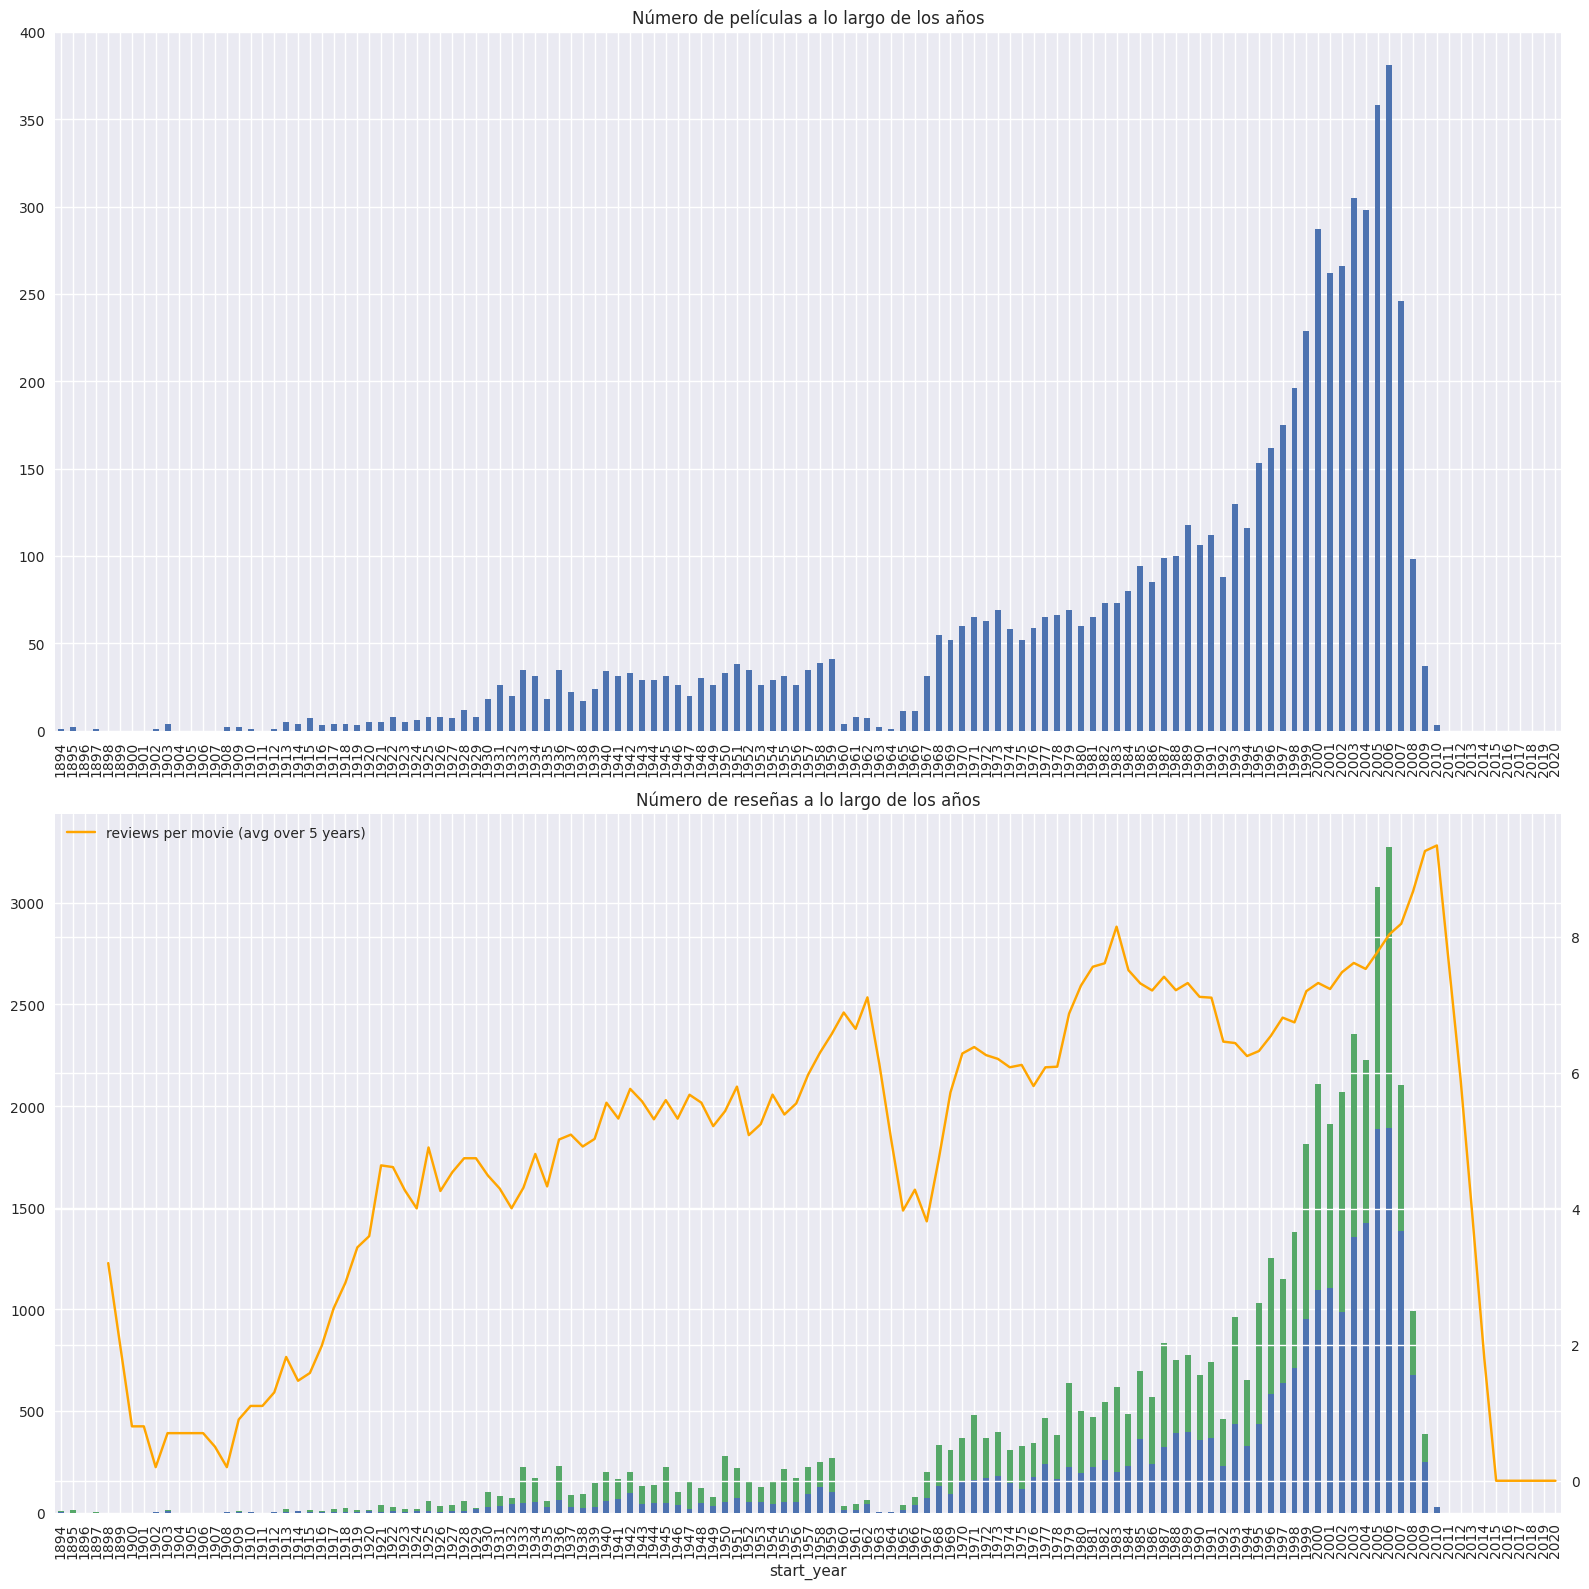

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 16))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

Veamos la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)

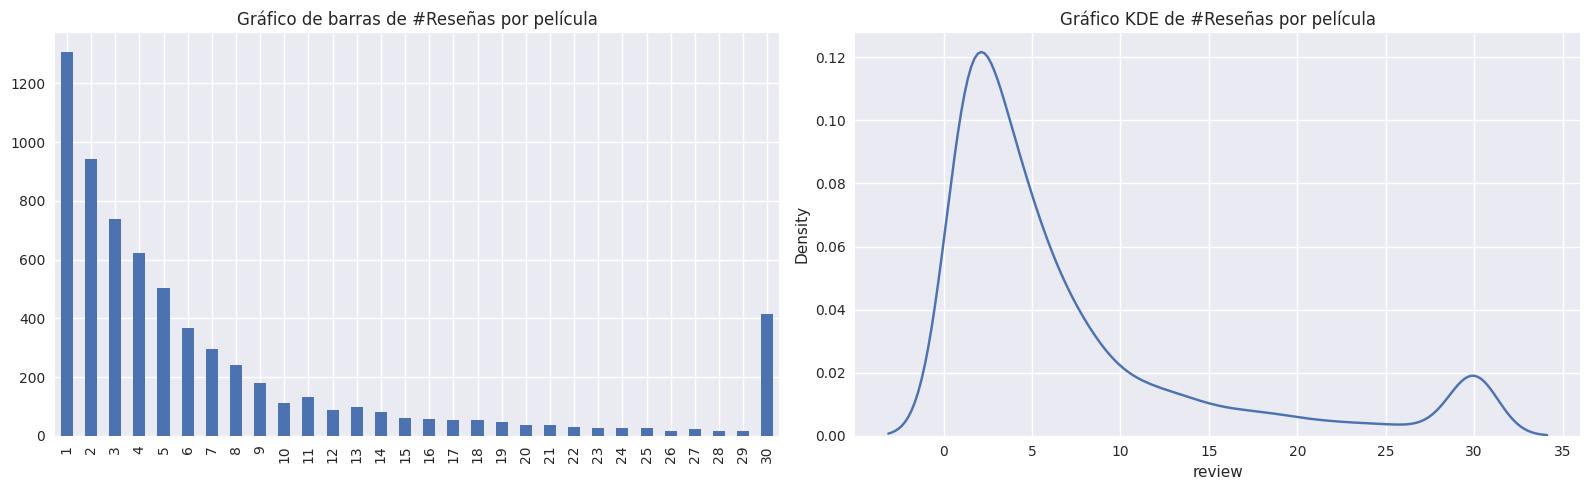

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

In [10]:
print('Número medio de reseñas por película:', df_reviews.groupby("tconst")['review'].count().mean().round(1))

Número medio de reseñas por película: 7.1


In [11]:
df_reviews['pos'].value_counts()

0    23715
1    23616
Name: pos, dtype: int64

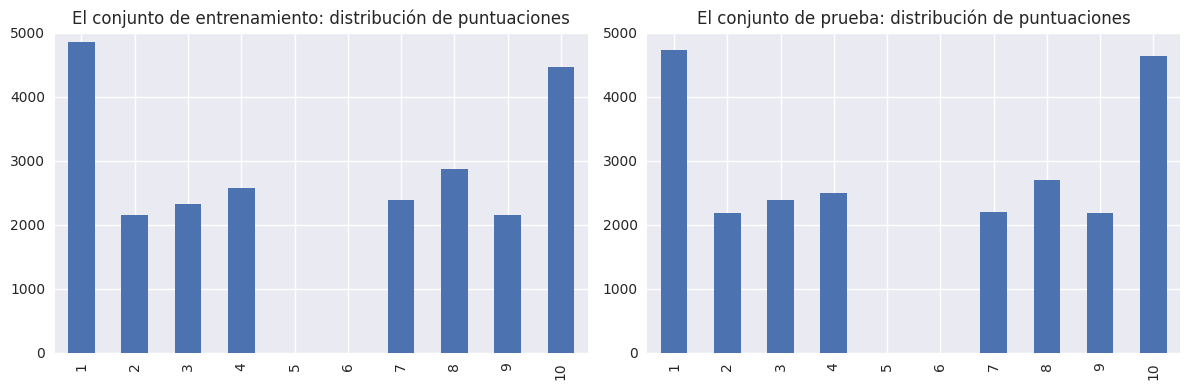

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

In [13]:
print('Puntuación media en el conjunto de entrenamiento:', df_reviews.query('ds_part == "train"')['rating'].mean().round(2))
print('Puntuación media en el conjunto de prueba:', df_reviews.query('ds_part == "test"')['rating'].mean().round(2))


Puntuación media en el conjunto de entrenamiento: 5.47
Puntuación media en el conjunto de prueba: 5.5


Distribución de reseñas negativas y positivas a lo largo de los años para dos partes del conjunto de datos

/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)


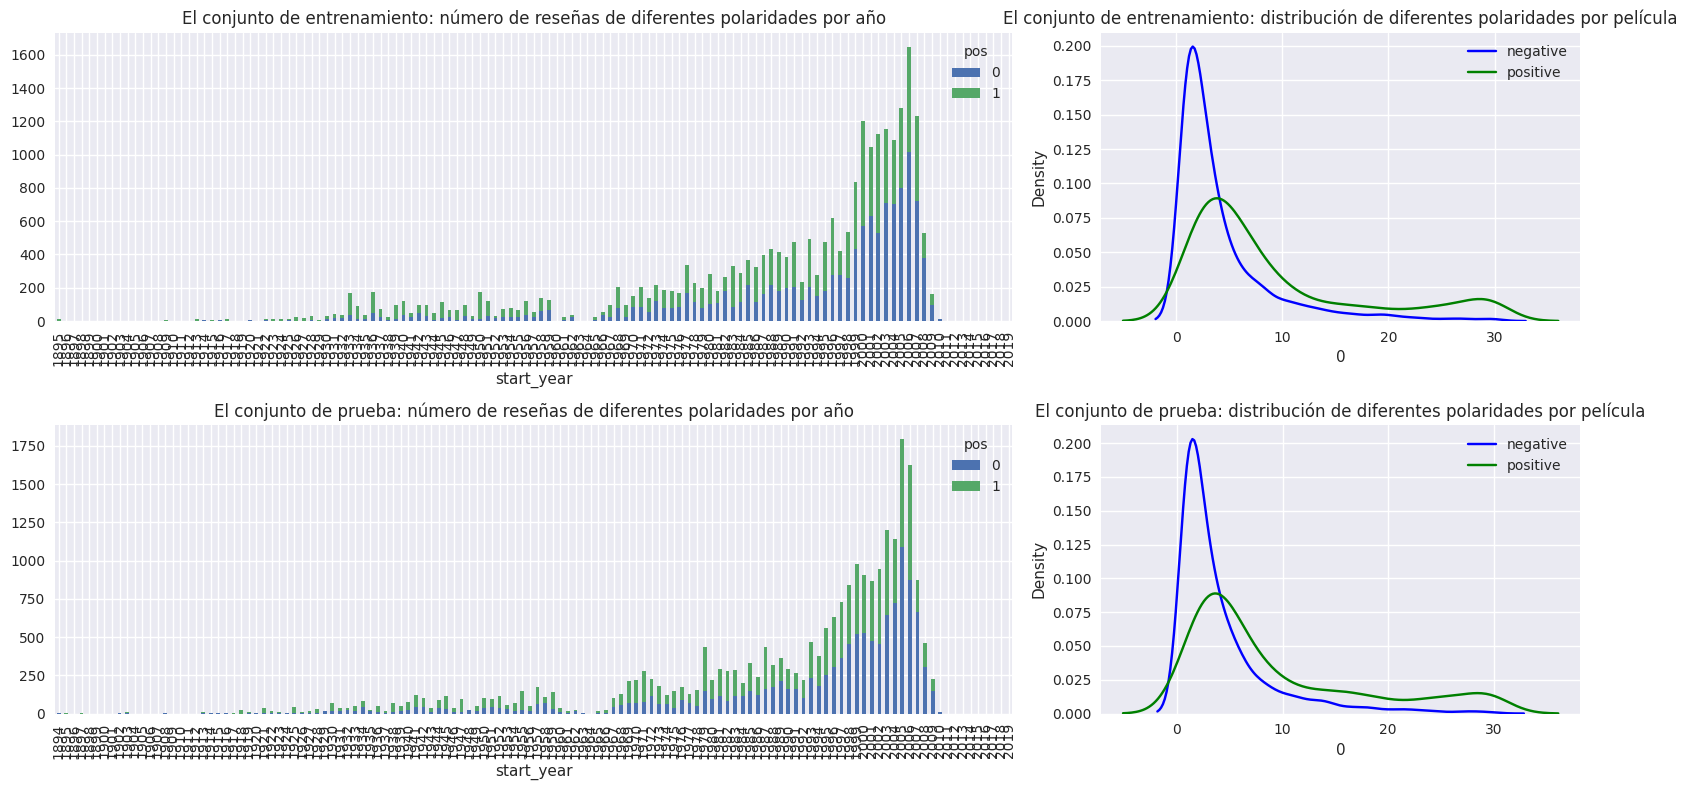

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

#### Observaciones
- Se puede observar que las reseñas positivas y negativas se encuentran balanceadas (23715 reseñas positivas y 23616 reseñas negativas).
- Por otro lado, las calificaciones promedio en los conjuntos de entrenamiento y prueba también se encuentran muy similares (calificación media de 5.47 para el conjunto de entrenamiento y 5.5 para el conjunto de prueba).
- Lo anterior y las gráficas adicionales dan a entender que los datos se encuentran **balanceados** y por lo tanto no se requiere aplicar tecnicas de sobremuestreo y submuestreo, y que al momento de revisar las métricas de F1Score o Accuracy, los resultados obtenidos en los entrenamientos podrán ser replicables en los conjuntos de prueba.


## Procedimiento de evaluación

Composición de una rutina de evaluación que se pueda usar para todos los modelos en este proyecto

In [15]:
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalización

Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

In [16]:
import re

#Creación de función de limpíeza de textos:
def clear_text(text):
    pattern = r"[^a-zA-Z']"
    text = re.sub(pattern, ' ', text)
    text = text.split()
    text = " ".join(text)
    return text.lower()
    
# Definición de la columna a procesar
df_reviews['review_norm'] = df_reviews['review'].apply(clear_text)

## División entrenamiento / prueba

Por fortuna, todo el conjunto de datos ya está dividido en partes de entrenamiento/prueba; 'ds_part' es el indicador correspondiente.

In [17]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabajar con modelos

### Modelo 0 - Constante

In [18]:
from sklearn.dummy import DummyClassifier

In [19]:
# Definición de características y modelo
train_features_0 = np.zeros((train_target.shape[0], 1))
test_features_0 = np.zeros((test_target.shape[0], 1))


model_0 = DummyClassifier(strategy='most_frequent', random_state=12345)

In [20]:
# Entrenamiento del model0
model_0.fit(train_features_0, train_target)

DummyClassifier(random_state=12345, strategy='most_frequent')

          train  test
Accuracy    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


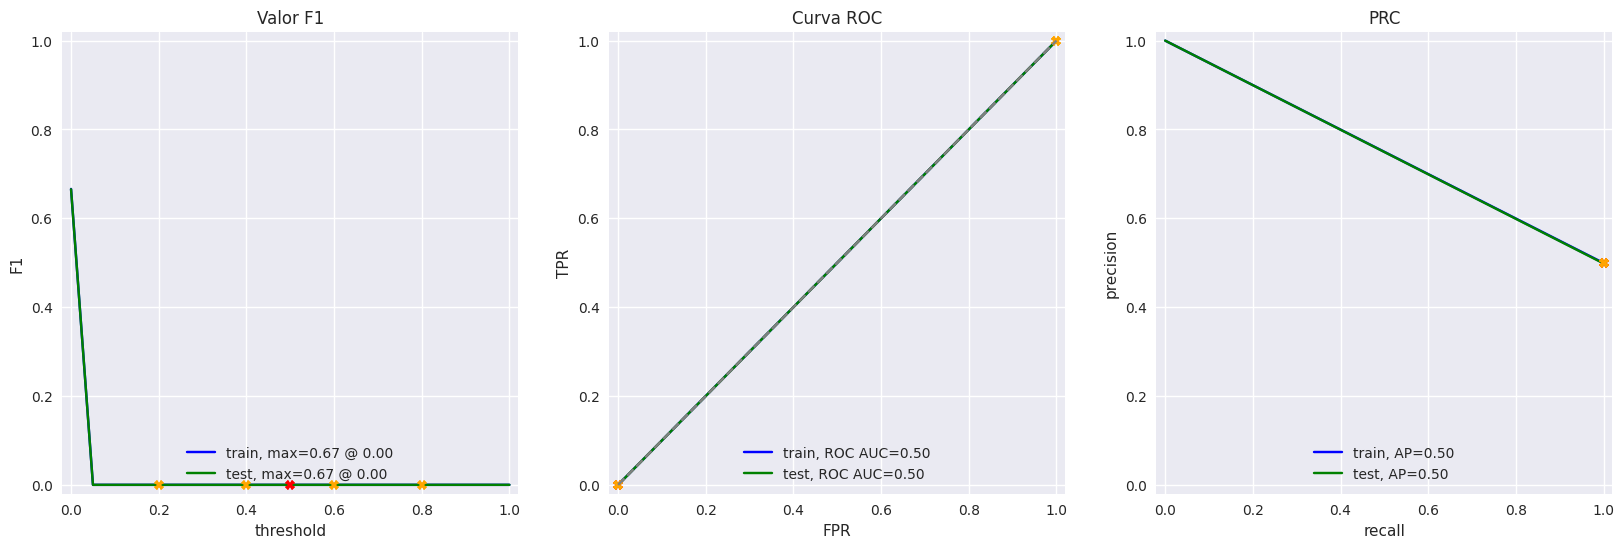

In [21]:
# Evaluación del modelo
evaluate_model(model_0, train_features_0, train_target, test_features_0, test_target)

#### Observaciones
- **Accuracy:** Para los sets de entrenamiento y prueba da 0.5. Esto es normal dado que los datos se encuentran balanceados desde su inicio y con un modelo de 0, acertaria aproximadamente la mitad de las veces.
- **F1:** En ambos sets da 0. Teniendo en cuenta que que el modelo siempre va a dar valores negativos (0), la formula de F1 que utiliza el Recall siempre dará un valor de 0.
- **APS:** Para un modelo constante, no tiene una capacidad de ordenar las clases y asigna la misma probabilidad a todas las observaciones y no realiza una discriminación real de valores positivos de negativos. El valor obtenido de 0.5 indica la proporción de clase positiva en el set.
- **ROC AUC:** Esta métrica mide la capacidad del modelo de ordenar y discriminar valores positivos y negativos correctamente. Entonces, un valor de AUC de 0.5 indica que el modelo discrimina igual que el azar.
- Por el lado gráfico, la curva **ROC** muestra que tanto los datos de entrenamiento y prueba están junto a la línea diagonal que tiene un contexto *"predice al azar"*. El modelo constante asigna siempre la probabilidad '0' a cualquier reseña.
- La curva de **valor F1** tiene un valor alto con un umbral de 0 y luego cae a 0 en los demas umbrales analizados. En un umbral igual a 0, El Recall será 1, la Precisión será de 0.5 y por ello el valor F1 será de 0.67.
- Finalmente, la curva **PRC** maneja 2 puntos: Recall=0/Precisión=1 y Recall=1/Precisión=0.5 y la curva obtenida es la recta que une ambos puntos.
- Como el modelo es una constante, se espera que se comporte igual en los juegos de entrenamiento y prueba y es por ello que las curvas aparecen superpuestas en los 3 gráficos.

### Modelo 1 - NLTK, TF-IDF y LR

TF-IDF

In [22]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [23]:
# Descargar idioma inglés de 'palabras vacias' y crear el vector quitando palabras vacías
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))
tfidf_vectorizer_1 = TfidfVectorizer(stop_words=stop_words)

# Formación set de características de entrenamiento y prueba
train_features_1 = tfidf_vectorizer_1.fit_transform(df_reviews_train['review_norm'])
test_features_1 = tfidf_vectorizer_1.transform(df_reviews_test['review_norm'])


In [24]:
# Entrenamiento del modelo
model_1 = LogisticRegression(random_state=12345, solver='liblinear')
model_1.fit(train_features_1, train_target)

LogisticRegression(random_state=12345, solver='liblinear')

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


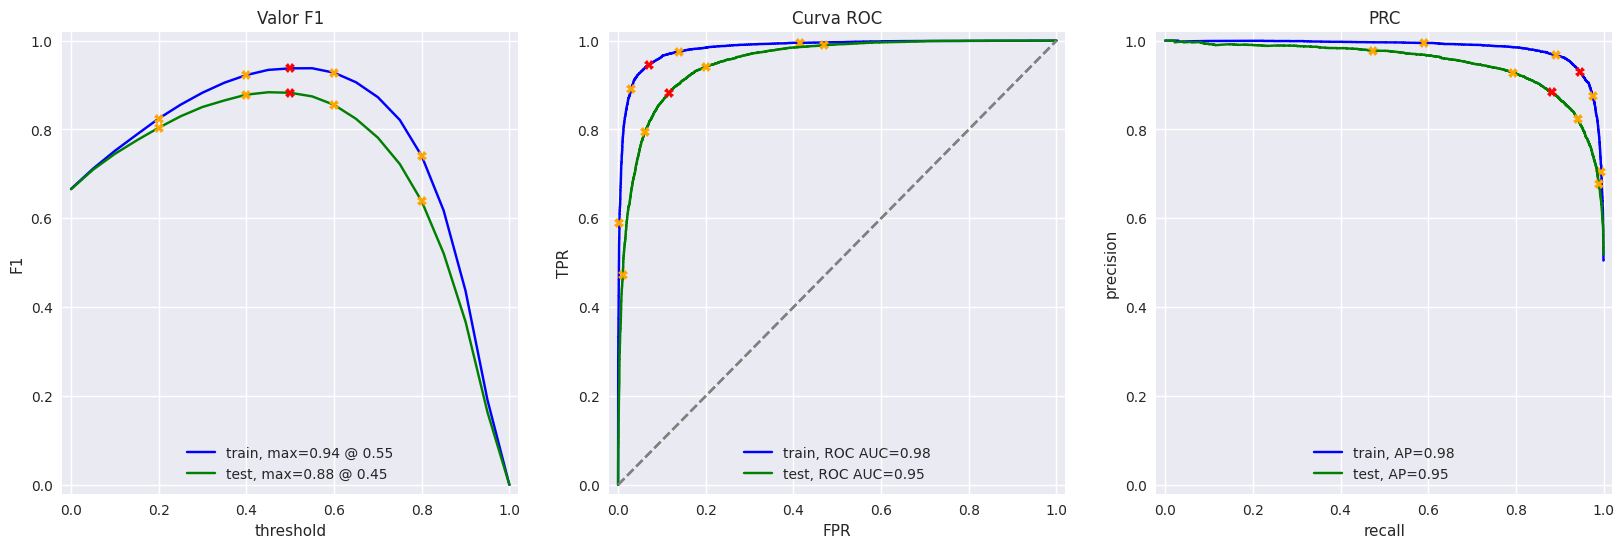

In [25]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

#### Observaciones
Para la regresión logística se obtuvieron datos interesantes
- El valor F1 aumento a 0.94 en el conjunto de entrenamiento y 0.88 en el conjunto de prueba. Este valor ya supera el umbral establecido en el proyecto y muestra un modelo que inicialmente puede servir para implementarse en nuestros datos.
- Comparado con los resultados del modelo constante, todas las métricas mejoran considerablemente. El *Accuracy* y el valor *F1* son iguales en ambos conjuntos de datos. Lo anterior muestra un balance adecuado en ambos conjuntos. La diferencia que se tiene entre los resultados de ambos conjuntos puede indicar un leve sobreajuste de los datos.
- Las curvas ROC y PRC para ambos juegos de datos se encuentran muy cercanas entre si, lo que termina de confirmar la consistencia en los datos y el modelo. Sin embargo, la curva ROC se encuentra bastante alejada de la diagonal que supone adivinar al azar, así que el modelo se encuentra bien entrenado y entrega valores confiables.

### Modelo 3 - spaCy, TF-IDF y LR

In [33]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [34]:
# Función de Lematización
def text_preprocessing_3(text):

    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]

    return ' '.join(tokens)

In [35]:
# Lematización y generación de los juegos de entrenamiento y prueba
df_reviews_train['review_norm_3'] = df_reviews_train['review_norm'].progress_apply(text_preprocessing_3)
df_reviews_test['review_norm_3'] = df_reviews_test['review_norm'].progress_apply(text_preprocessing_3)

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23535 [00:00<?, ?it/s]

In [36]:
# Creación de vector sin palabras vacías
tfidf_vectorizer_3 = TfidfVectorizer(stop_words=stop_words)

# Generación sets de entrenamiento y prueba para el modelo
train_features_3 = tfidf_vectorizer_3.fit_transform(df_reviews_train['review_norm_3'])
test_features_3 = tfidf_vectorizer_3.transform(df_reviews_test['review_norm_3'])


          train  test
Accuracy   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


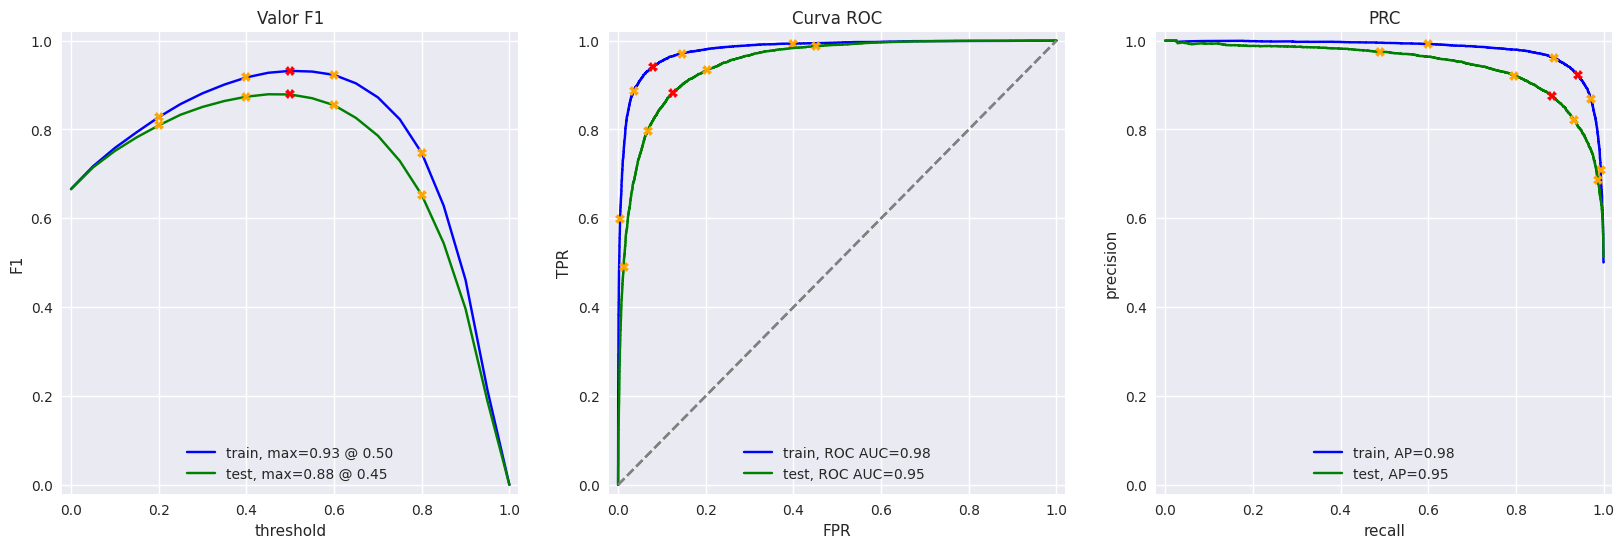

In [37]:
# Aplicación modelo regresión logística
model_3 = LogisticRegression(random_state=12345, solver='liblinear')
model_3.fit(train_features_3, train_target)

# Evaluación del modelo
evaluate_model(model_3, train_features_3, train_target, test_features_3, test_target)

#### Observaciones
En este caso, las reseñas pasan por un proceso de lematización antes de ser sometidas al entrenamiento.
- El Accuracy obtenido es de 0.93 para el set de entrenamiento y 0.88 para el de prueba, disminuye levemente sobre el modelo anterior para el entrenamiento y es igual en el de prueba. Esto se debe a la lematización, que puede reducir levemente el vocabulario, sin embargo, no son datos negativos para el modelo. 
- Al igual que con NLTK, el valor *F1* es igual al *accuracy*. Esto sigue confirmando el balanceo de las clases en ambos juegos. Se sigue superando el umbral establecido de 0.85.
- Los valores *APS* y *ROC-AUC* tampoco varían comparados con el modelo NLTK. Esto muestra que el modelo 'separa adecuadamente' las reseñas positivas y negativas.
- Este modelo alcanza su valor máximo en un umbral de 0.5, mientras el modelo anterior alcanzaba su valor máximo en un umbral de 0.55. Si bien ambos umbrales son cercanos, esto indicaría que el modelo no requiere ajustes de umbral adicionales.
- Como único punto que pueda tomarse como negativo, es el alto costo computacional que se realiza para hacer la lematización. En este punto el modelo NLTK arroja resultados muy similares con un costo de computo mucho menor.

### Modelo 4 - spaCy, TF-IDF y LGBMClassifier

In [38]:
from lightgbm import LGBMClassifier

In [39]:
# Creación de vectores y conjuntos de características para entrenamiento y prueba (como se realiza con spaCy, se toman los mismos datos del modelo anterior)
tfidf_vectorizer_4 = tfidf_vectorizer_3

train_features_4 = train_features_3
test_features_4 = test_features_3

In [40]:
# Aplicación del modelo
model_4 = LGBMClassifier(random_state=12345, verbose=-1)
model_4.fit(train_features_4, train_target)

LGBMClassifier(random_state=12345, verbose=-1)

          train  test
Accuracy   0.91  0.86
F1         0.91  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


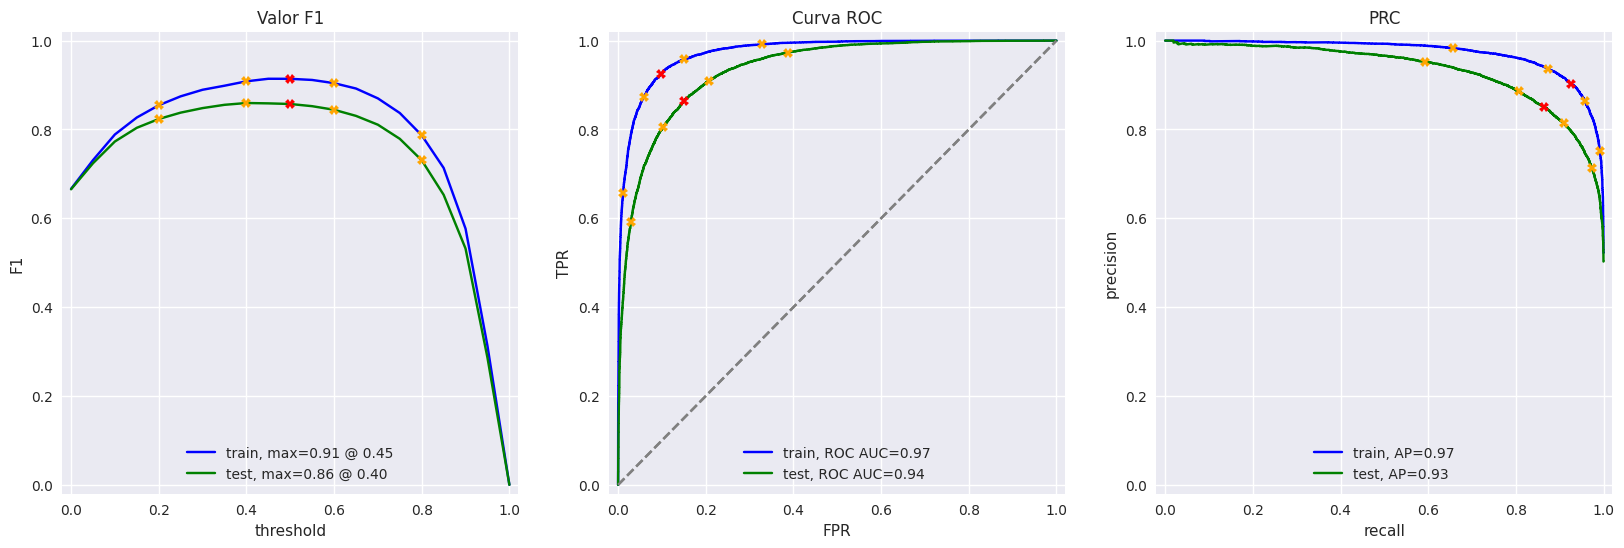

In [41]:
# Evaluación de métricas
evaluate_model(model_4, train_features_4, train_target, test_features_4, test_target)

#### Observaciones
En este modelo se toman las mismas características del modelo inmediatamente anterior y se cambia el modelo de clasificación a un modelo LightGBM.
- En este modelo las métricas analizadas quedan por debajo de las métricas obtenidas con Regresión logística. Esto se explica debido a que una matriz TF-IDF tiene muchas columnas de palabras de vocabulario presente en las reseñas con muchos ceros. Esta matriz presenta una alta dispersión y dimensionalidad. Un modelo como LightGBM combina muchos árboles de manera secuencial, buscando relaciones no-lineales, afectando su eficiencia. 
- La curva *F1* si bien es similar al modelo de regresión logística, presenta un comportamiento menor en su curva. Las curvas *ROC* y *PRC* también muestran un poco esta tendencia.
- Los valores de **F1** siguen estando por encima del umbral establecido, pero sus valores son menores a los obtenidos con los modelos de **Regresión logística**.
- *Si bien este modelo es mas complejo, no presenta los mejores resultados.*

###  Modelo 9 - BERT

In [26]:
import torch
import transformers

In [27]:
# Carga modelo BERT
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.seq_relationship.weight', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [28]:
def BERT_text_to_embeddings(texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False):

    ids_list = []
    attention_mask_list = []

    # texto al id de relleno de tokens junto con sus máscaras de atención
    for text in texts:
        ids = tokenizer.encode(text.lower(), add_special_tokens=True, truncation=True, max_length=max_length)
        padded = np.array(ids + [0] * (max_length - len(ids)))
        attention_mask = np.where(padded !=0, 1, 0)
        ids_list.append(padded)
        attention_mask_list.append(attention_mask)

    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model.to(device)
    if not disable_progress_bar:
        print(f'Uso del dispositivo {device}.')

    # obtener insertados en lotes

    embeddings = []

    for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        ids_batch = torch.LongTensor(np.array(ids_list[batch_size*i:batch_size*(i+1)])).to(device)
        attention_mask_batch = torch.LongTensor(np.array(attention_mask_list[batch_size*i:batch_size*(i+1)])).to(device)
        
        with torch.no_grad():
            model.eval()
            batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)
        embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())

    return np.concatenate(embeddings)

In [29]:
# ¡Atención! La ejecución de BERT para miles de textos puede llevar mucho tiempo en la CPU, al menos varias horas
# Ajuste a muestra de 100 reseñas
bert_sample_size = 100

# Definición juegos de entrenamiento y prueba para modelo BERT
df_reviews_train_9 = df_reviews_train.sample(bert_sample_size, random_state=12345)
df_reviews_test_9 = df_reviews_test.sample(bert_sample_size, random_state=12345)

# Definición juegos objetivos entrenamiento y prueba para modelo BERT
train_target_9 = df_reviews_train_9['pos']
test_target_9 = df_reviews_test_9['pos']

# Juego características de entrenamiento y prueba para modelo BERT
train_features_9 = BERT_text_to_embeddings(df_reviews_train_9['review_norm'], batch_size=10)
test_features_9 = BERT_text_to_embeddings(df_reviews_test_9['review_norm'], batch_size=10)

Uso del dispositivo cpu.


  0%|          | 0/10 [00:00<?, ?it/s]

Uso del dispositivo cpu.


  0%|          | 0/10 [00:00<?, ?it/s]

In [30]:
# Corroboración de tamaño de juegos de entrenamiento y prueba
print(df_reviews_train_9['review_norm'].shape)
print(train_features_9.shape)
print(train_target_9.shape)
print(test_features_9.shape)
print(test_target_9.shape)

(100,)
(100, 768)
(100,)
(100, 768)
(100,)


In [31]:
# Aplicación del modelo
model_9 = LogisticRegression(random_state=12345, solver='liblinear')
model_9.fit(train_features_9, train_target_9)

LogisticRegression(random_state=12345, solver='liblinear')

          train  test
Accuracy    1.0  0.78
F1          1.0  0.76
APS         1.0  0.83
ROC AUC     1.0  0.85


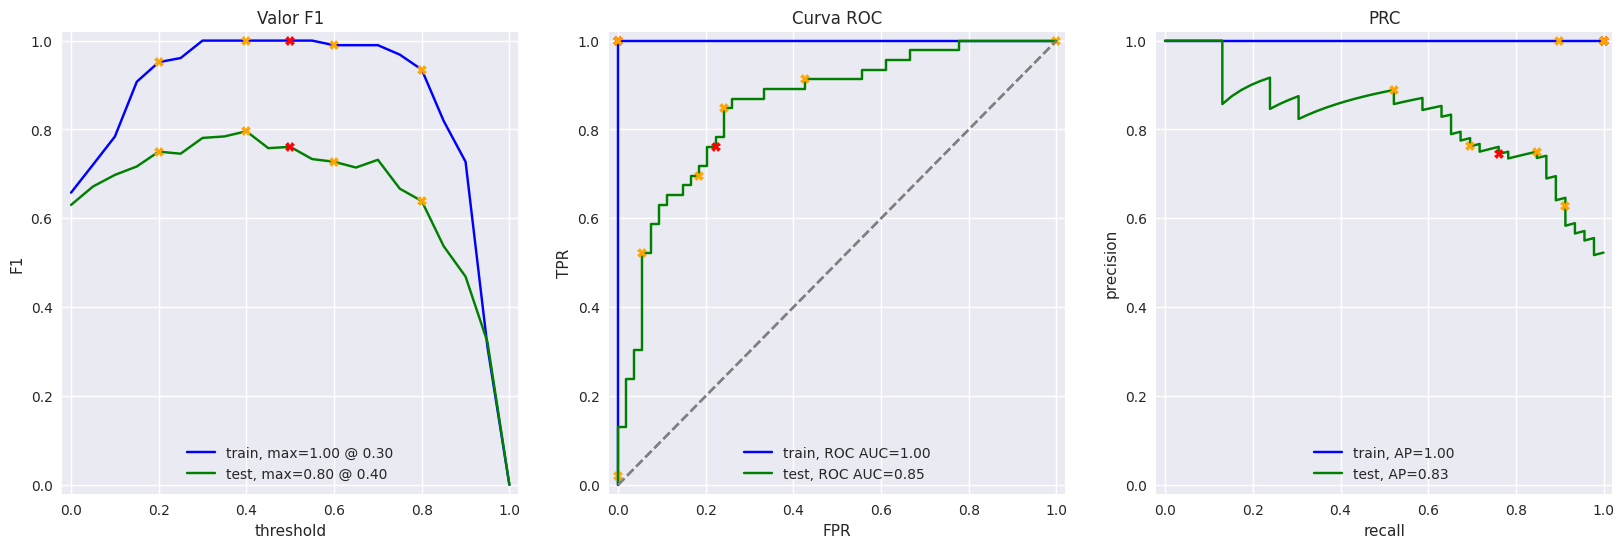

In [32]:
# Evaluación modelo
evaluate_model(model_9, train_features_9, train_target_9, test_features_9, test_target_9)

#### Observaciones
Para poder aplicar este modelo de manera adecuada con un costo computacional pequeño hubo que realizar algunas modificaciones. Pero basado en esto se encuentra:
- El modelo tuvo unas métricas perfectas para el juego de entrenamiento. Esto no es un dato positivo realmente ya que indica que el modelo 'memorizó' el conjunto de entrenamiento y no identificó patrones para predecir.
- Por ello, la alta diferencia en las métricas del conjunto de entrenamiento y prueba. Esto indica un valor de sobreajuste severo. Esto se debe a que la regresión se realiza con solo 100 observaciones o reseñas donde cada fila tiene 768 columnas, es decir, hay menos ejemplos que características.
- Bajo este panorama, la métrica **F1** para el set de prueba tiene valor que no supera el umbral establecido.
- En este caso, si bien el modelo BERT es el modelo más complejo disponible, es el que peores predicciones entrega. Esto es causado por el bajo número de reseñas con que se entrena el modelo comparado con los otros modelos estudiados.
- La curva azul en la gráfica de F1 revela el sobreajuste mencionado.
- Con una mejor disponibilidad de computo, el modelo BERT debería entregar los mejores resultados, pero con un entrenamiento con solo 100 muestras, resulta muy dificil establecer tendencias y conexiones reales para otras observaciones.
- Sin embargo, el disponer de modelos robustos con bajo costo computacional, permite presentar resultados fiables como los obtenidos en los modelos anteriores, sin sacrificar el resultado final del proyecto.

In [ ]:
# si ya obtuviste los insertados, te recomendamos guardarlos para tenerlos listos si
# np.savez_compressed('features_9.npz', train_features_9=train_features_9, test_features_9=test_features_9)

# y cargar...
# with np.load('features_9.npz') as data:
#     train_features_9 = data['train_features_9']
#     test_features_9 = data['test_features_9']

## Mis reseñas

In [43]:
# Aplicación con reseñas propias

my_reviews = pd.DataFrame([
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    'I didn\'t expect the reboot to be so good! Writers really cared about the source material',
    'The movie had its upsides and downsides, but I feel like overall it\'s a decent flick. I could see myself going to see it again.',
    'What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won\'t like this!',
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.'
], columns=['review'])

"""
my_reviews = pd.DataFrame([
    'Simplemente no me gustó, no es mi tipo de película.',
    'Bueno, estaba aburrido y me quedé dormido a media película.',
    'Estaba realmente fascinada con la película',
    'Hasta los actores parecían muy viejos y desinteresados, y les pagaron por estar en la película. Qué robo tan desalmado.',
    '¡No esperaba que el relanzamiento fuera tan bueno! Los escritores realmente se preocuparon por el material original',
    'La película tuvo sus altibajos, pero siento que, en general, es una película decente. Sí la volvería a ver',
    'Qué pésimo intento de comedia. Ni una sola broma tiene sentido, todos actúan de forma irritante y ruidosa, ¡ni siquiera a los niños les gustará esto!',
    'Fue muy valiente el lanzamiento en Netflix y realmente aprecio poder seguir viendo episodio tras episodio de este nuevo drama tan emocionante e inteligente.'
], columns=['review'])
"""

my_reviews['review_norm'] = my_reviews['review'].apply(clear_text)
my_reviews

,review,review_norm
0,"I did not simply like it, not my kind of movie.",i did not simply like it not my kind of movie
1,"Well, I was bored and felt asleep in the middl...",well i was bored and felt asleep in the middle...
2,I was really fascinated with the movie,i was really fascinated with the movie
3,Even the actors looked really old and disinter...,even the actors looked really old and disinter...
4,I didn't expect the reboot to be so good! Writ...,i didn't expect the reboot to be so good write...
5,"The movie had its upsides and downsides, but I...",the movie had its upsides and downsides but i ...
6,What a rotten attempt at a comedy. Not a singl...,what a rotten attempt at a comedy not a single...
7,Launching on Netflix was a brave move & I real...,launching on netflix was a brave move i really...


### Modelo 2

In [45]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(tfidf_vectorizer_1.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.14:  i did not simply like it not my kind of movie
0.16:  well i was bored and felt asleep in the middle of the movie
0.54:  i was really fascinated with the movie
0.11:  even the actors looked really old and disinterested and they got paid to be in the movie what a soul
0.31:  i didn't expect the reboot to be so good writers really cared about the source material
0.47:  the movie had its upsides and downsides but i feel like overall it's a decent flick i could see myse
0.04:  what a rotten attempt at a comedy not a single joke lands everyone acts annoying and loud even kids 
0.82:  launching on netflix was a brave move i really appreciate being able to binge on episode after episo


### Modelo 3

In [46]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_3.predict_proba(tfidf_vectorizer_3.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.20:  i did not simply like it not my kind of movie
0.12:  well i was bored and felt asleep in the middle of the movie
0.49:  i was really fascinated with the movie
0.10:  even the actors looked really old and disinterested and they got paid to be in the movie what a soul
0.27:  i didn't expect the reboot to be so good writers really cared about the source material
0.50:  the movie had its upsides and downsides but i feel like overall it's a decent flick i could see myse
0.03:  what a rotten attempt at a comedy not a single joke lands everyone acts annoying and loud even kids 
0.92:  launching on netflix was a brave move i really appreciate being able to binge on episode after episo


### Modelo 4

In [47]:
texts = my_reviews['review_norm']

tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.53:  i did not simply like it not my kind of movie
0.40:  well i was bored and felt asleep in the middle of the movie
0.60:  i was really fascinated with the movie
0.38:  even the actors looked really old and disinterested and they got paid to be in the movie what a soul
0.73:  i didn't expect the reboot to be so good writers really cared about the source material
0.61:  the movie had its upsides and downsides but i feel like overall it's a decent flick i could see myse
0.26:  what a rotten attempt at a comedy not a single joke lands everyone acts annoying and loud even kids 
0.80:  launching on netflix was a brave move i really appreciate being able to binge on episode after episo


### Modelo 9

In [48]:
texts = my_reviews['review_norm']

my_reviews_features_9 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.04:  i did not simply like it not my kind of movie
0.03:  well i was bored and felt asleep in the middle of the movie
0.70:  i was really fascinated with the movie
0.01:  even the actors looked really old and disinterested and they got paid to be in the movie what a soul
0.10:  i didn't expect the reboot to be so good writers really cared about the source material
0.19:  the movie had its upsides and downsides but i feel like overall it's a decent flick i could see myse
0.09:  what a rotten attempt at a comedy not a single joke lands everyone acts annoying and loud even kids 
0.83:  launching on netflix was a brave move i really appreciate being able to binge on episode after episo


## Conclusiones

### Resumen comparativo
Los principales resultados fueron: 

| Modelo | Características | Clasificador | Valor F1 |
| --- | --- | --- |--- |
| Modelo 0 | Constante | DummyClassifier | Valores de referencia para los otros modelos |
| Modelo 1 | TF-IDF / NLTK | Regresión logística | 0.88 |
| Modelo 3 | TF-IDF / Lematizado con spaCy | Regresión logística | 0.88 |
| Modelo 4 | TF-IDF / Lematizado con spaCy | LightGBM | 0.86 |
| Modelo 9 | BERT (muestra 100) | Regresión logística | 0.76 |

**Hallazgos:**
- El modelo constante se presenta como modelo de cordura y es la base de comparación de los demas modelos entrenados.
- Los modelos basados de TF-IDF y entrenados con *Regresión logística* son modelos que presentan resultados fuertes para clasificación de textos y son rápidos de entrenar.
- La lematización básica (NLTK) comparada con la realizada con spaCy no muestra diferencias significativas en sus métricas finales. Si bien las métricas son ligeramente inferiores, el costo computacional es elevado y no compensa en un resultado final.
- El modelo TF-IDF entrenado con LightGBM tampoco supera el modelo de Regresión logística, esto debido a la alta dispersión y dimensionalidad de las matrices de características formadas. En este caso un modelo más complejo no significa un modelo mejor.
- El modelo BERT en este caso particular a pesar de ser un modelo complejo y confiable, por los recursos disponibles solo pudo entrenarse con una muestra de 100 reseñas, lo que impidió tener un valor de F1 que pudiera superar el umbral permitido y muestra un sobreajuste severo.
  

### Diferencias de reseñas propias (my_reviews) con el conjunto de prueba

El resumen de resultados es el siguiente:

| Reseña | M1 | M3 | M4 | M9 |
| --- | --- | --- | --- | --- |
| 1. "I did not simply like it..." | 0.14 | 0.20 | **0.53** | 0.04 |
| 2. "well i was bored and felt asleep..." | 0.16 | 0.12 | 0.40 | 0.03 |
| 3. "i was really fascinated..." | 0.54 | 0.49 | 0.60 | 0.70 |
| 4. "even the actors looked really old..." | 0.11 | 0.10 | 0.38 | 0.01 |
| 5. "i didn't expect the reboot to be so good..." | 0.31 | 0.27 | **0.73** | 0.10 |
| 6. "the movie had its upsides and downsides..." | 0.47 | 0.50 | 0.61 | 0.19 |
| 7. "what a rotten attempt at a comedy..." | 0.04 | 0.03 | 0.26 | 0.09 |
| 8. "launching on netflix was a brave move..." | 0.82 | 0.92 | 0.80 | 0.83 |

- Observando la reseña 5 se encuentra un dato interesante. La reseña es claramente positiva, sin embargo 3 de los 4 modelos la clasifican como negativa, ya que usa una frase de negación y a continuación presenta un dato positivo. Como el modelo de 'bolsa de palabras' no identifica el orden de las palabras, la presencia de un "didn´t" contamina la clasificación.
- Como el modelo BERT esta tan sobreajustado, incluso este modelo falla en la predicción de la calificación.
- Se observa un buen concenso en reseñas 1, 2, 4, 7 y 8. En este caso los modelos funcionaron adecuadamente.
- Las reseñas 3 y 6 al no ser "obvias" presentan una incertidumbre clara. Si un texto es ambiguo, el modelo debe mostrar esta incertidumbre.
- El modelo **LightGBM** es menos extremo en sus resultados con reseñas claras, esto muestra los errores de calibración presentados en el entrenamiento y las razones de su falibilidad.
- El modelo **BERT** presenta los resultados mas extremos, síntoma claro de su sobreajuste.

#### Conclusión final

- Se realiza un trabajo de procesamiento en un grupo de datos limpio y balanceado. Esto permite obtener unas métricas de *accuracy* y *F1* confiables y comparables, sin necesidad de ajustarlas por algún desequilibrio.
- Se procesan datos de reseñas de películas cubriendo varias configuraciones de lematización (bolsa de palabras, BERT, lematizado con spaCy), y modelos de clasificación (regresión logística, LightGBM) para entrenar modelos de predicción de valoración positiva o negativa de reseñas. Un modelo constante se utiliza como línea base de comparación y la métrica de *valor F1* se usa para evaluar estos modelos, los cuales deben superar un umbral de *0.85*.
- Bajo estas condiciones, se obtiene que los modelos de *Regresión logística* y *LightGBM* con una lematización NLTK o spaCy superan ampliamente el umbral establecido.
- En este punto el costo computacional se convierte en factor de decisión para determinar que **un modelo de Regresión logística y lematizado NLTK entrega los mejores resultados** con un costo computacional óptimizado.
- A pesar de los resultados obtenidos, se encuentra que una reseña que tenga un lenguaje ambiguo, con ironia o sarcasmo puede afectar las predicciones finales del modelo.
- El modelo BERT se pudo probar con una muestra reducida, pero los resultados no superaron el umbral definido. Los recursos de computo para utilizar esta clase de modelos son grandes y salen del objetivo del proyecto.

# Lista de comprobación

- [x]  Abriste el notebook
- [x]  Cargaste y preprocesaste los datos de texto para su vectorización
- [x]  Transformaste los datos de texto en vectores
- [x]  Entrenaste y probaste los modelos
- [x]  Se alcanzó el umbral de la métrica
- [x]  Colocaste todas las celdas de código en el orden de su ejecución
- [x]  Puedes ejecutar sin errores todas las celdas de código
- [x]  Hay conclusiones